In [ ]:
# LIDAR Data Processing Tutorial in Python
# This tutorial uses 'laspy' for reading LAS/LAZ files and 'open3d' for 3D processing and visualization.

# 1. Install necessary libraries
#!pip install laspy[lazrs] open3d numpy

import laspy
import open3d as o3d

import numpy as np
import matplotlib.pyplot as plt

print("Libraries successfully imported!")

Libraries successfully imported!


In [ ]:
# --- Step 2: Creating Dummy LIDAR Data for Demonstration ---
# In a real scenario, you would load your file using:
# las = laspy.read("your_file.las")

print("\n--- Step 1: Generating synthetic LIDAR data (since we don't have a local .las file) ---")
# Create a synthetic ground plane and some obstacles
num_points = 50000
x = np.random.uniform(-50, 50, num_points)
y = np.random.uniform(-50, 50, num_points)
# Ground surface with slight slopes + some elevated points (representing buildings/trees)
z = 0.05 * x + 0.02 * y + np.random.normal(0, 0.1, num_points)

# Add some obstacles (e.g., structures)
num_obstacles = 10000
x_obs = np.random.uniform(-10, 10, num_obstacles)
y_obs = np.random.uniform(-10, 10, num_obstacles)
z_obs = np.random.uniform(0, 10, num_obstacles)

x = np.concatenate([x, x_obs])
y = np.concatenate([y, y_obs])
z = np.concatenate([z, z_obs])

points = np.vstack((x, y, z)).T
print(f"Generated synthetic point cloud with {points.shape[0]} points.")


--- Step 1: Generating synthetic LIDAR data (since we don't have a local .las file) ---
Generated synthetic point cloud with 60000 points.


In [ ]:
def plot_pcd(points,title_string):
  # --- Step 2b: Visualizing the 3D Point Cloud ---
  # We will use matplotlib's 3D plotting capabilities to display a subset of our LIDAR points.
  fig = plt.figure(figsize=(10, 8))
  ax = fig.add_subplot(projection='3d')

  plt.style.use('dark_background')

  # Plotting a subset (e.g., 5,000 points) to ensure the notebook remains responsive
  sample_indices = np.random.choice(len(points), size=5000, replace=False)
  sampled_points = points[sample_indices]

  # Scatter plot colored by elevation (Z coordinate)
  scatter = ax.scatter(
      sampled_points[:, 0],
      sampled_points[:, 1],
      sampled_points[:, 2],
      c=sampled_points[:, 2],
      cmap='terrain',
      s=2
  )

  fig.colorbar(scatter, ax=ax, label='Elevation (Z)')
  ax.set_title(title_string)
  ax.set_xlabel('X')
  ax.set_ylabel('Y')
  ax.set_zlabel('Z')
  ax.set_xlim(-50, 50)
  ax.set_ylim(-50, 50)
  ax.set_zlim(-5, 10)

  plt.show()

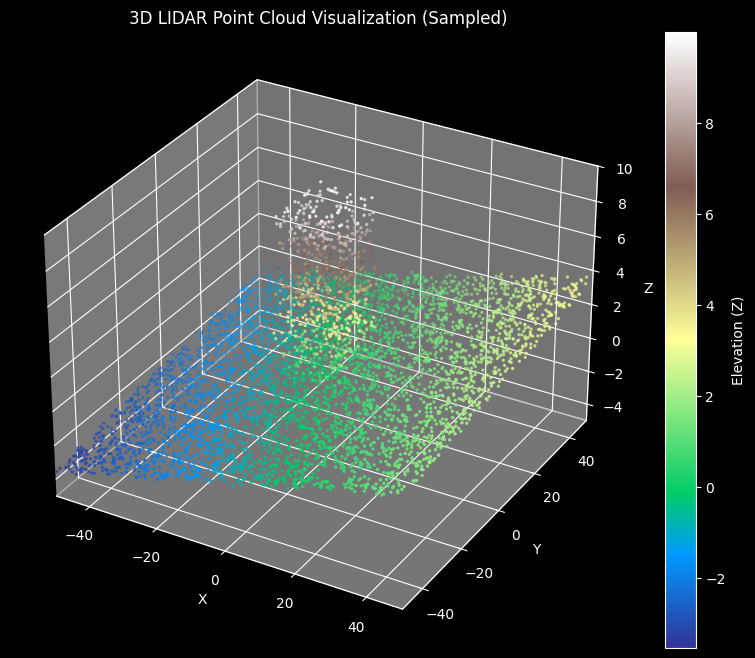

In [ ]:
plot_pcd(points,"3D LIDAR Point Cloud Visualization (Sampled)")

In [ ]:
# --- Step 3: Convert to Open3D Point Cloud for Processing ---
print("\n--- Step 2: Converting points to Open3D PointCloud format ---")
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)


--- Step 2: Converting points to Open3D PointCloud format ---


In [ ]:
# --- Step 4: Downsampling (Voxel Grid Filter) ---
# This reduces the number of points by grouping them into voxels and averaging, which speeds up processing.
print("\n--- Step 3: Downsampling point cloud ---")
voxel_size = 0.5
downsampled_pcd = pcd.voxel_down_sample(voxel_size=voxel_size)
print(f"Original points: {len(pcd.points)} | Downsampled points: {len(downsampled_pcd.points)}")


--- Step 3: Downsampling point cloud ---
Original points: 60000 | Downsampled points: 41087


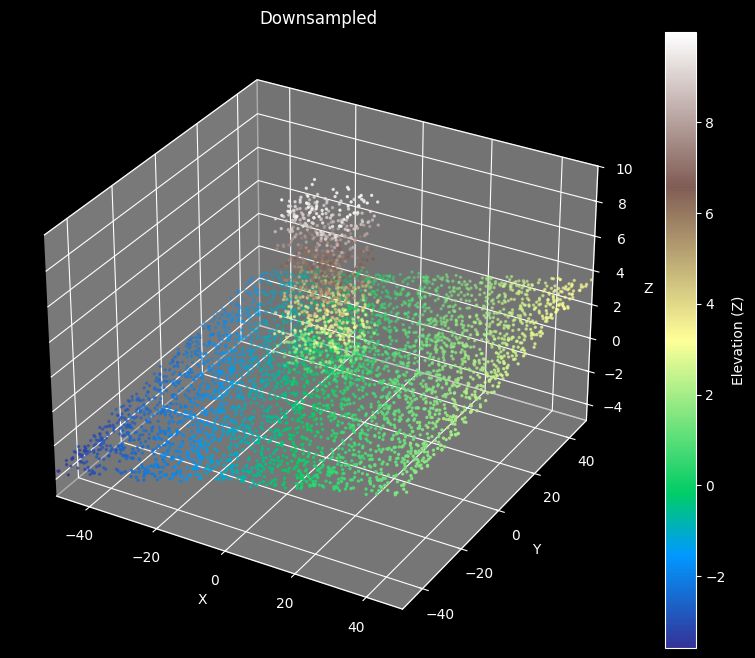

In [ ]:
# Convert Open3D Vector3dVector points to a numpy array first, then plot
plot_pcd(np.asarray(downsampled_pcd.points),"Downsampled")

In [ ]:
# --- Step 5: Noise and Outlier Removal ---
# LIDAR data often contains noise. We can filter outliers using statistical outlier removal.
print("\n--- Step 4: Removing statistical outliers ---")
cl, ind = downsampled_pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)
filtered_pcd = downsampled_pcd.select_by_index(ind)
print(f"Filtered points (outliers removed): {len(filtered_pcd.points)}")


--- Step 4: Removing statistical outliers ---
Filtered points (outliers removed): 39810


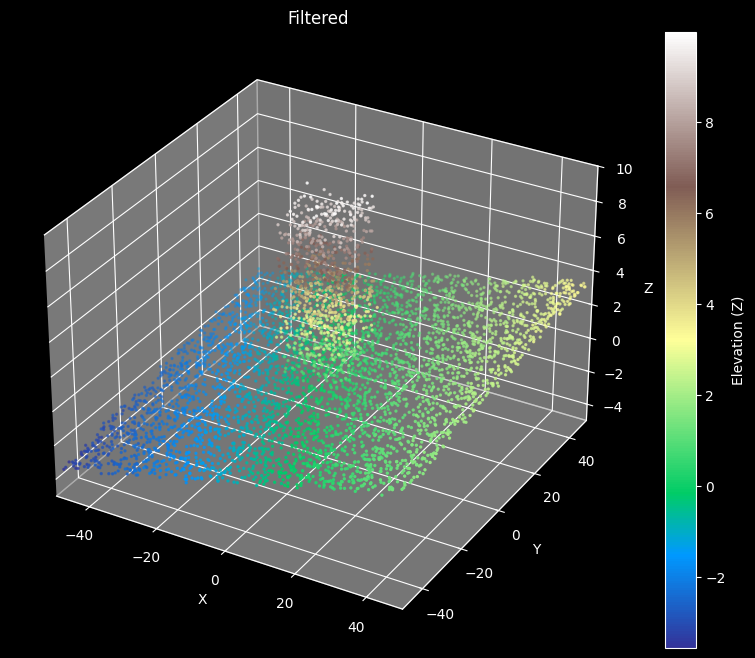

In [ ]:
# Convert Open3D Vector3dVector points to a numpy array first, then plot
plot_pcd(np.asarray(filtered_pcd.points),"Filtered")

In [ ]:
# --- Step 6: Segmentation (Finding the Ground Plane) ---
# RANSAC is commonly used to detect geometric primitives like planes (ground) in LIDAR data.
print("\n--- Step 5: Segmenting the ground plane using RANSAC ---")
plane_model, inliers = filtered_pcd.segment_plane(distance_threshold=0.3, ransac_n=3, num_iterations=1000)
[a, b, c, d] = plane_model
print(f"Plane equation: {a:.2f}x + {b:.2f}y + {c:.2f}z + {d:.2f} = 0")

# Separate ground (inliers) and non-ground/objects (outliers)
ground_pcd = filtered_pcd.select_by_index(inliers)
objects_pcd = filtered_pcd.select_by_index(inliers, invert=True)

print(f"Ground plane points: {len(ground_pcd.points)}")
print(f"Above-ground object points: {len(objects_pcd.points)}")



--- Step 5: Segmenting the ground plane using RANSAC ---
Plane equation: -0.05x + -0.02y + 1.00z + 0.00 = 0
Ground plane points: 31897
Above-ground object points: 7913


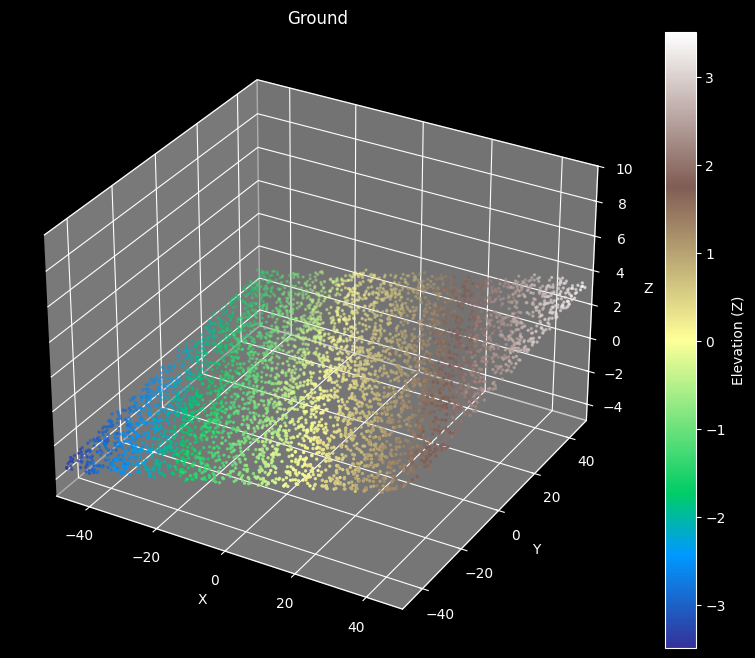

In [ ]:
# Convert Open3D Vector3dVector points to a numpy array first, then plot
plot_pcd(np.asarray(ground_pcd.points),"Ground")

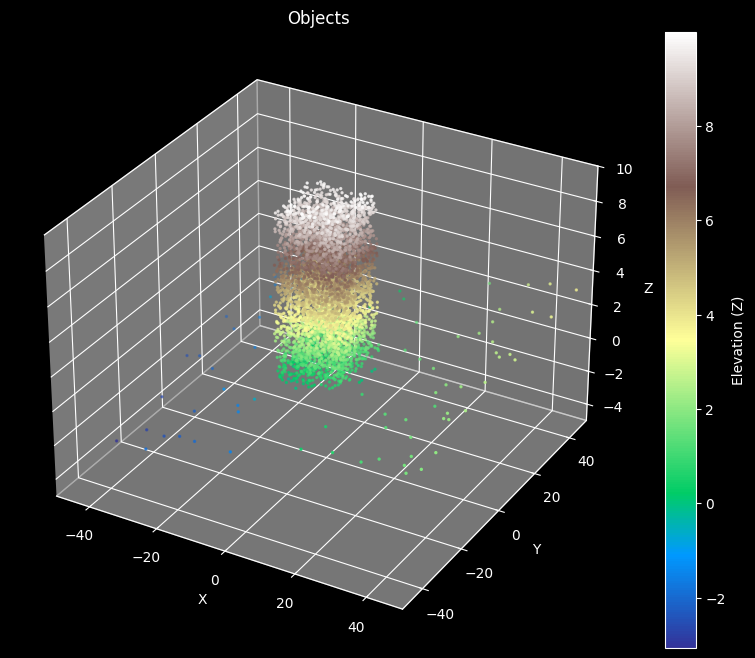

In [ ]:
# Convert Open3D Vector3dVector points to a numpy array first, then plot
plot_pcd(np.asarray(objects_pcd.points),"Objects")